In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet('../data/processed/01_data.parquet')
universo = pd.read_parquet('../data/processed/01_universo_tgt.parquet')

meses_train = ['2018-08-01', '2018-09-01', '2018-10-01', '2018-11-01', '2018-12-01', '2019-01-01']
df_train = df[df['Month'].isin(meses_train)]
data_train = universo[['client_id']].merge(df_train, how='inner', on='client_id')

print(data_train.shape)   # (139146, 77)

(139146, 77)


# Limpieza

## Objetivo
Corregir los datos faltantes o inconsistentes de la ventana de entrenamiento (ago 2018 – ene 2019), antes de construir la ABT.

## Entrada
- 01_data.parquet: base completa con client_id corregido (238.615 filas).
- 01_universo_tgt.parquet: 23.191 clientes con su target.

A partir de ellos se arma data_train: los 6 meses de entrenamiento, solo para los clientes del universo (139.146 filas).

## Pasos
1. SavingAccount_Balance_Average: 4 nulos. Se estiman con saldo inicial + créditos − débitos del mismo mes.
2. Region: 100% nula en train, porque el banco la registra desde marzo 2019. Como es estable por cliente, se toma de marzo–abril. Sin dato → "Sin dato".
3. CreditCard_Product: 100% nula en train. Si el cliente no tenía tarjeta en enero → "No tiene". Si tenía, se toma el tipo de marzo; si no aparece, se asigna el más frecuente.
4. Outliers: screening de todas las variables numéricas, análisis en detalle de tres montos en pesos (saldo, transferencias entrantes y salientes), revisión de valores imposibles y capping en el p95.

## Salida
- 02_data_train_limpio.parquet y 02_data_tarj.parquet

# Nulos

In [3]:
nulos = data_train.isnull().sum()

resumen_nulos = pd.DataFrame({
    'cantidad': nulos,
    'porcentaje': (nulos / len(data_train) * 100).round(2)
})
resumen_nulos[resumen_nulos['cantidad'] > 0].sort_values('cantidad', ascending=False)

,cantidad,porcentaje
Region,139146,100.0
CreditCard_Product,139146,100.0
SavingAccount_Balance_Average,4,0.0


Hay tres variables con valores nulos en la ventana de entrenamiento. Region y CreditCard_Product están 100% vacías porque el banco empezó a registrarlas en marzo de 2019; se imputan con el valor de cada cliente en marzo/abril, ya que son atributos estables. SavingAccount_Balance_Average tiene solo 4 nulos, que se estiman con saldo inicial + créditos − débitos del mismo mes.

## 1. SavingAccount_Balance_Average

In [4]:
data_train[data_train['SavingAccount_Balance_Average'].isnull()][['client_id', 'Month', 'SavingAccount_Balance_Average']]

,client_id,Month,SavingAccount_Balance_Average
5684,4525957,2019-01-01,NaN
23231,6412619,2019-01-01,NaN
67814,4837071,2018-12-01,NaN
90229,4473325,2018-12-01,NaN


In [5]:
estimado = data_train['SavingAccount_Balance_FirstDate'] \
         + data_train['SavingAccount_Credits_Amounts'] \
         - data_train['SavingAccount_Debits_Amounts']

data_train['SavingAccount_Balance_Average'] = data_train['SavingAccount_Balance_Average'].fillna(estimado)

In [6]:
print(data_train['SavingAccount_Balance_Average'].isnull().sum())   # tiene que dar 0

0


## 2. Region

In [7]:
# Porcentaje de nulos por mes
df.groupby('Month')['Region'].apply(lambda s: s.isnull().mean())

Month
2018-08-01    1.000000
2018-09-01    1.000000
2018-10-01    1.000000
2018-11-01    1.000000
2018-12-01    1.000000
2019-01-01    1.000000
2019-02-01    1.000000
2019-03-01    0.000264
2019-04-01    0.000264
Name: Region, dtype: float64

In [8]:
# Confirmar que cada cliente tiene una sola región
df.groupby('client_id')['Region'].nunique().value_counts()

Region
1    26544
0       16
Name: count, dtype: int64

In [9]:
# Traigo la región de marzo/abril a data_train
tabla_region = (df.dropna(subset=['Region'])
                  .sort_values('Month')
                  .groupby('client_id')['Region']
                  .last())

data_train['Region'] = data_train['client_id'].map(tabla_region)
data_train['Region'] = data_train['Region'].fillna('Sin dato')

In [10]:
print(data_train['Region'].isnull().sum())   # tiene que dar 0
data_train['Region'].value_counts()

0


Region
BUENOS AIRES                     41904
REGION CENTRO                    27474
REGION NORTE GRANDE ARGENTINO    22044
REGION PATAGONICA                14592
CABA Centro/Norte                12288
AMBA Resto                       10968
REGION CUYO                       9840
Sin dato                            36
Name: count, dtype: int64

Conclusión – Region: la variable está 100% vacía hasta febrero de 2019 y se registra a partir de marzo. Como cada cliente tiene una única región, se imputa con la informada en marzo/abril. Los 6 clientes (36 filas) sin región en ningún mes quedan como "Sin dato".

## 3. CreditCard_Product

In [11]:
data_tarj = data_train[data_train['Month'] == '2019-01-01'][['client_id', 'CreditCard_Active']]
print(data_tarj.shape)   # (23191, 2)

(23191, 2)


In [12]:
tarj_marzo = df[df['Month'] == '2019-03-01'][['client_id', 'CreditCard_Product']]
data_tarj = data_tarj.merge(tarj_marzo, how='left', on='client_id')

In [13]:
data_tarj['CreditCard_Product'] = np.where(data_tarj['CreditCard_Active'] == 'Yes',
                                           data_tarj['CreditCard_Product'],
                                           'No tiene')

In [14]:
moda = data_tarj[data_tarj['CreditCard_Active'] == 'Yes']['CreditCard_Product'].mode()[0]
data_tarj['CreditCard_Product'] = data_tarj['CreditCard_Product'].fillna(moda)

In [15]:
print(data_tarj['CreditCard_Product'].isnull().sum())   # tiene que dar 0
data_tarj['CreditCard_Product'].value_counts()

0


CreditCard_Product
J55660104XX012    8508
No tiene          8168
J55660202XX012    5777
J55660102XX012     402
J55660702XX012     248
J55661002XX012      58
J55660124XX012      29
J55660123XX012       1
Name: count, dtype: int64

Conclusión – CreditCard_Product: si el cliente no tenía tarjeta en enero de 2019 se asigna "No tiene". Si tenía, se toma el tipo informado en marzo de 2019, bajo el supuesto de que el tipo de tarjeta es estable en el tiempo; si no aparece, se asigna el tipo más frecuente.

# Outliers

## Screening
Para cada variable numérica se compara el máximo contra el p99 (max_vs_p99): cuanto mayor es el cociente, más extrema es la cola de la distribución.

In [16]:
numericas = data_train.select_dtypes('number').drop(columns=['client_id', 'Target'])

resumen = pd.DataFrame({
    'p99': numericas.quantile(0.99),
    'max': numericas.max()
})
resumen['max_vs_p99'] = resumen['max'] / resumen['p99']
resumen.sort_values('max_vs_p99', ascending=False).head(15)

,p99,max,max_vs_p99
SavingAccount_Transfer_Out_Transactions,0.0000,25.00,inf
SavingAccount_Transfer_Out_Amount,21453.0140,2916500.00,135.948263
SavingAccount_Transfer_In_Amount,43000.0000,1948500.00,45.313953
SavingAccount_Salary_Payment_Amount,58568.9505,2551357.60,43.561607
SavingAccount_Balance_FirstDate,80397.6975,2693270.87,33.499353
SavingAccount_Balance_LastDate,81145.1685,2410283.59,29.703353
CreditCard_Balance_DOLLAR,132.9365,3933.55,29.589691
SavingAccount_CreditCard_Payment_Amount,33823.0500,962295.93,28.450892
CreditCard_Spending_CrossBoarder,143.6205,4000.25,27.852918
SavingAccount_Transfer_In_Transactions,4.0000,104.00,26.000000


- Las variables de montos en pesos concentran las colas más extremas: transferencias salientes (136x), entrantes (45x) y sueldos (44x).
- SavingAccount_Transfer_Out_Transactions da infinito porque su p99 es 0: más del 99% de las filas no tiene transferencias salientes. No es un problema de outliers, sino una variable casi vacía.
- Las variables en dólares también tienen cola larga, pero se descartan porque el análisis se enfoca en montos en pesos.

A partir de este screening se eligen tres variables en pesos para el análisis en detalle: saldo promedio (lo que el cliente tiene), transferencias entrantes (lo que le entra) y transferencias salientes (lo que le sale).

## Análisis en detalle
Para cada variable se analizan solo los valores mayores a 0 (los ceros son clientes sin ese movimiento). Se comparan tres límites posibles (regla IQR, p95 y p99) y se grafica el boxplot y el histograma. Debido a la fuerte asimetría de los montos, los gráficos se presentan en escala logarítmica: en escala lineal, el valor máximo comprime la distribución y no permite distinguir la caja del boxplot.

In [17]:
def analizar_outliers(data, col):
    s = data[col]
    pos = s[s > 0]                                   # solo montos positivos
    q1, q3 = pos.quantile([0.25, 0.75])
    lim_iqr = q3 + 1.5 * (q3 - q1)                   # límite regla IQR
    p95, p99 = pos.quantile([0.95, 0.99])

    print(col)
    print(f'  Filas en 0: {(s == 0).mean():.1%} | Negativos: {(s < 0).sum()}')
    print(f'  Mediana (>0): {pos.median():,.0f} | Máximo: {pos.max():,.0f}')

    tabla = pd.DataFrame({
        'limite': [lim_iqr, p95, p99],
        'pct_filas_arriba': [(pos > lim_iqr).mean(), (pos > p95).mean(), (pos > p99).mean()]
    }, index=['IQR (Q3 + 1,5*IQR)', 'p95', 'p99'])
    display(tabla.style.format({'limite': '{:,.0f}', 'pct_filas_arriba': '{:.1%}'}))

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.boxplot(x=pos, ax=ax[0])
    ax[0].set_xscale('log')
    ax[0].set_title(f'{col} (valores > 0, escala log)')
    sns.histplot(np.log10(pos), bins=50, ax=ax[1])
    for v in [p95, p99]:
        ax[1].axvline(np.log10(v), color='red', linestyle='--')
    ax[1].set_title('Distribución en log10 (líneas: p95 y p99)')
    plt.tight_layout()
    plt.show()

### SavingAccount_Balance_Average

SavingAccount_Balance_Average
  Filas en 0: 43.7% | Negativos: 224
  Mediana (>0): 1,100 | Máximo: 1,771,201


,limite,pct_filas_arriba
"IQR (Q3 + 1,5*IQR)","10,579",13.1%
p95,"30,767",5.0%
p99,"107,114",1.0%


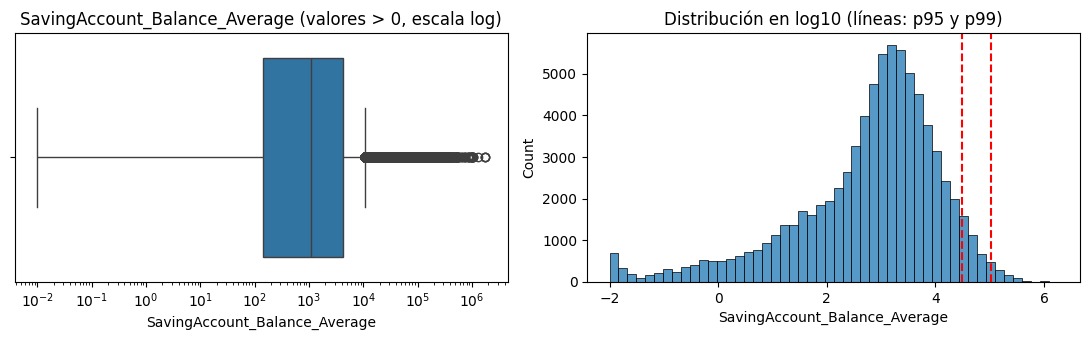

In [18]:
analizar_outliers(data_train, 'SavingAccount_Balance_Average')

Conclusión: el 43,7% de las filas tiene saldo 0 y hay 224 negativos (ver Valores imposibles). Entre los saldos positivos, la mediana es \$1.100 y el máximo \$1.771.201. La regla IQR marcaría como atípico al 13,1% de los clientes, un criterio demasiado agresivo para una distribución tan asimétrica. Se aplica capping en el p95 (\$30.767).

### SavingAccount_Transfer_Out_Amount

SavingAccount_Transfer_Out_Amount
  Filas en 0: 95.2% | Negativos: 0
  Mediana (>0): 7,000 | Máximo: 2,916,500


,limite,pct_filas_arriba
"IQR (Q3 + 1,5*IQR)","41,550",10.6%
p95,"76,452",5.0%
p99,"239,150",1.0%


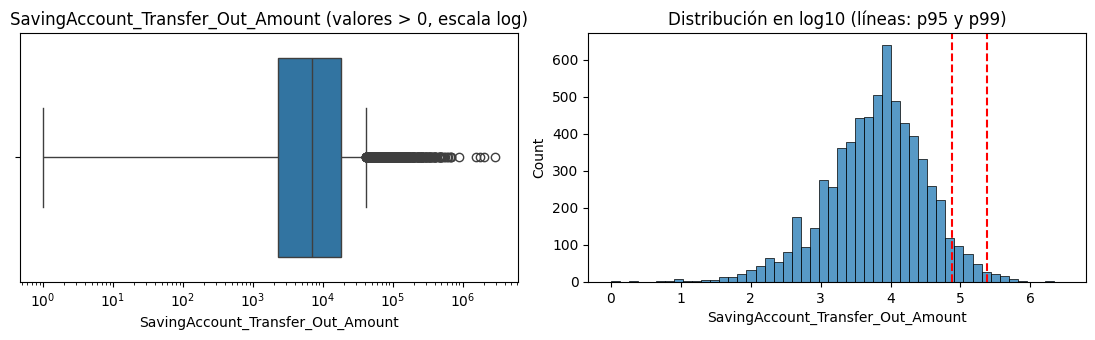

In [19]:
analizar_outliers(data_train, 'SavingAccount_Transfer_Out_Amount')

Conclusión: es la variable con la cola más extrema (máximo 136 veces el p99). El 95,2% de las filas está en 0: muy pocos clientes realizan transferencias salientes. Entre los que transfieren, la mediana es \$7.000 y el máximo \$2.916.500. La regla IQR marcaría como atípico al 10,6%. Se aplica capping en el p95 (\$76.452).

### SavingAccount_Transfer_In_Amount

SavingAccount_Transfer_In_Amount
  Filas en 0: 79.8% | Negativos: 0
  Mediana (>0): 6,000 | Máximo: 1,948,500


,limite,pct_filas_arriba
"IQR (Q3 + 1,5*IQR)","27,486",10.0%
p95,"42,833",5.0%
p99,"105,455",1.0%


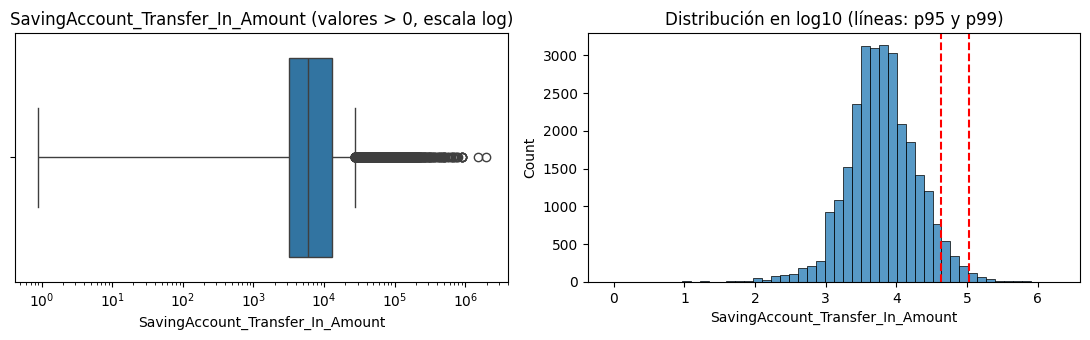

In [20]:
analizar_outliers(data_train, 'SavingAccount_Transfer_In_Amount')

Conclusión: el 79,8% de las filas está en 0. Entre los clientes que reciben transferencias, la mediana es \$6.000 y el máximo \$1.948.500. La regla IQR marcaría como atípico al 10%. Se aplica capping en el p95 (\$42.833).

## Valores imposibles
Se revisan valores que podrían indicar errores de carga: saldos negativos y días de uso mayores a los días del mes.

In [21]:
negativos = data_train[data_train['SavingAccount_Balance_Average'] < 0]
print(negativos.shape[0])
negativos['SavingAccount_Balance_Average'].describe()

224


count    224.000000
mean      -3.822277
std       42.366645
min     -566.590000
25%       -0.010000
50%       -0.010000
75%       -0.010000
max       -0.010000
Name: SavingAccount_Balance_Average, dtype: float64

In [22]:
data_train['SavingAccount_Days_with_use'].describe()

count    139146.000000
mean          2.512685
std           3.831400
min           0.000000
25%           0.000000
50%           0.000000
75%           4.000000
max          41.000000
Name: SavingAccount_Days_with_use, dtype: float64

Conclusión – valores imposibles:
- Hay 224 saldos negativos, casi todos de −\$0,01. Se consideran reales (descubiertos mínimos) y no se modifican.
- SavingAccount_Days_with_use llega a 41, más que los días de un mes. No es un error: la variable suma los días de uso de todas las cajas de ahorro del cliente, y esos clientes tienen más de una cuenta.

## Tratamiento: capping en el p95

In [23]:
vars_outliers = ['SavingAccount_Balance_Average',
                 'SavingAccount_Transfer_Out_Amount',
                 'SavingAccount_Transfer_In_Amount']

limites_capping = {}
for col in vars_outliers:
    limite = data_train.loc[data_train[col] > 0, col].quantile(0.95)
    limites_capping[col] = limite
    data_train[col] = data_train[col].clip(upper=limite)

# Verificación: el máximo de cada variable ahora es igual a su límite
pd.DataFrame({'limite_p95': limites_capping,
              'max_despues': data_train[vars_outliers].max()}).round(0)

,limite_p95,max_despues
SavingAccount_Balance_Average,30767.0,30767.0
SavingAccount_Transfer_Out_Amount,76452.0,76452.0
SavingAccount_Transfer_In_Amount,42833.0,42833.0


Conclusión – outliers: las tres variables presentan una distribución fuertemente asimétrica a la derecha. Los valores extremos no son errores, sino clientes con alto volumen transaccional, por lo que no se eliminan. Se aplica capping en el p95 de los valores positivos: se conservan todas las filas y se limita la influencia de los extremos. Los límites quedan guardados en limites_capping para aplicar los mismos valores al momento del scoring.

## Guardado

In [24]:
data_train.to_parquet('../data/processed/02_data_train_limpio.parquet', index=False)
data_tarj.to_parquet('../data/processed/02_data_tarj.parquet', index=False)

print(data_train.shape)   # (139146, 77)
print(data_tarj.shape)    # (23191, 3)

(139146, 77)
(23191, 3)
